# Martian topography and marsquakes

Shun Lok Wong & Qili Andy Dai

Aerospace Science and Earth Informatics Double Major Program  
Department of Earth and Environmental Sciences  

Contact: qilidai@cuhk.edu.hk

How can we connect a seismic signal recorded on Mars to an impact crater seen from orbit? This tutorial brings together three datasets that capture different aspects of the same problem. Mars Orbiter Laser Altimeter (MOLA) elevations show the regional terrain around the InSight landing site and let us measure large craters such as Jezero. HiRISE imagery reveals fresh craters too small to resolve in the MOLA grid, and the InSight catalogue records the seismic signals associated with confirmed impacts.

By working through these datasets, you will see how spatial resolution determines what can be measured, how orbital images help confirm an impact, and what eight confirmed events can tell us about the relationship between crater diameter and seismic magnitude.

### Running this notebook

Run the cells in order with a Python 3 kernel. Data are cached in `mars_data/` and figures are written to `figures/` under the working directory. If you download the MOLA GeoTIFF separately, place it in `mars_data/` under its original filename, `Mars_MGS_MOLA_DEM_mosaic_global_463m.tif`. The download cell will reuse the local file.

## 1. Set up the environment and working folders

If dependencies are missing, run this command in a separate notebook cell and restart the kernel.

```python
%pip install numpy matplotlib rasterio lxml scipy pillow
```

Use the output below to check the package versions and the working directory before downloading the data.

In [18]:
import sys
import time
import math
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import lxml.etree as ET

import rasterio
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

print('python      ', sys.version.split()[0])
print('numpy       ', np.__version__)
print('matplotlib  ', matplotlib.__version__)
print('rasterio    ', rasterio.__version__)
print('lxml        ', '.'.join(map(str, ET.LXML_VERSION[:3])))

python       3.9.23
numpy        2.0.2
matplotlib   3.9.4
rasterio     1.4.3
lxml         6.0.2


In [19]:
ROOT = Path.cwd()
DATA = ROOT / 'mars_data'
FIGS = ROOT / 'figures'

for folder in (DATA, FIGS):
    folder.mkdir(parents=True, exist_ok=True)

assert DATA.is_dir() and FIGS.is_dir()

print('working folder:', ROOT)
print('data folder   :', DATA)
print('figures folder:', FIGS)

working folder: /Users/qilidai/Desktop/CUHK/ug_students/mars_impact
data folder   : /Users/qilidai/Desktop/CUHK/ug_students/mars_impact/mars_data
figures folder: /Users/qilidai/Desktop/CUHK/ug_students/mars_impact/figures


Existing data and figures can be reused when you run the notebook again.

## 2. Download the MOLA topography

The USGS 463 m MOLA digital elevation model is a single-band GeoTIFF with 46,080 columns and 23,040 rows. It uses an equirectangular projection with coordinates in metres and east-positive longitude. Elevations are measured relative to the Martian areoid.

The download helper retries failed requests and resumes a partial file when the server supports byte ranges.

In [20]:
import urllib.request

MOLA_URL = ('https://planetarymaps.usgs.gov/mosaic/'
            'Mars_MGS_MOLA_DEM_mosaic_global_463m.tif')
MOLA = DATA / 'Mars_MGS_MOLA_DEM_mosaic_global_463m.tif'


def _size(n):
    return f'{n / 1e9:.2f} GB' if n >= 1e8 else f'{n / 1e6:.1f} MB'


def fetch(url, dest, min_bytes=1, chunk=8 << 20):
    # stream url into dest; resume a .part file, retry, verify the size
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size >= min_bytes:
        print(f'cached  {dest.name}  {_size(dest.stat().st_size)}')
        return dest
    part = dest.with_name(dest.name + '.part')
    for attempt in range(1, 4):
        pos = part.stat().st_size if part.exists() else 0
        headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) mars-tutorial/1.0',
                   'Accept': '*/*'}
        if pos:
            headers['Range'] = f'bytes={pos}-'
        try:
            req = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(req, timeout=90) as resp:
                if pos and resp.status != 206:
                    pos = 0
                    part.unlink(missing_ok=True)
                total = int(resp.headers.get('Content-Length', 0)) + pos
                mode = 'ab' if pos else 'wb'
                with open(part, mode) as fh:
                    while True:
                        block = resp.read(chunk)
                        if not block:
                            break
                        fh.write(block)
                        pos += len(block)
                        if total:
                            print(f'\r  {_size(pos)} / {_size(total)}', end='')
            print()
            if part.stat().st_size >= min_bytes:
                part.replace(dest)
                return dest
            print(f'attempt {attempt}: file short, retrying')
        except Exception as err:
            print(f'attempt {attempt} failed: {err}')
            time.sleep(5)
    raise RuntimeError(f'download failed after 3 attempts: {url}')

In [21]:
fetch(MOLA_URL, MOLA, min_bytes=1_900_000_000)
print(f'file size: {MOLA.stat().st_size / 1e9:.2f} GB')

cached  Mars_MGS_MOLA_DEM_mosaic_global_463m.tif  2.13 GB
file size: 2.13 GB


Open the GeoTIFF and check its dimensions, data type and pixel spacing. These checks help confirm you have the expected MOLA product before you start plotting.

In [22]:
with rasterio.open(MOLA) as src:
    print('width, height :', src.width, src.height)
    print('bands, dtype  :', src.count, src.dtypes[0])
    print('crs           :', src.crs)
    print('pixel size    :', src.transform.a, src.transform.e)
    print('bounds        :', tuple(round(v, 3) for v in src.bounds))
    print('nodata        :', src.nodata)

    assert src.width == 46080 and src.height == 23040
    assert src.dtypes[0] == 'int16'
    assert abs(src.res[0] - 463.09) < 0.5

width, height : 46080 23040
bands, dtype  : 1 int16
crs           : PROJCS["Equirectangular Mars",GEOGCS["GCS_Mars",DATUM["D_Mars",SPHEROID["Mars_localRadius",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
pixel size    : 463.0935415503709 -463.0935415503709
bounds        : (-10669675.197, -5334837.599, 10669675.197, 5334837.599)
nodata        : -32768.0


PROJCS["Equirectangular Mars",GEOGCS["GCS_Mars",DATUM["D_Mars",SPHEROID["Mars_localRadius",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
pixel size    : 463.0935415503709 -463.0935415503709
bounds        : (-10669675.197, -5334837.599, 10669675.197, 5334837.599)
nodata        : -32768.0


The projection uses a spherical Mars radius of 3,396,190 m. At the equator, the 463.09 m pixel spacing corresponds to 128 pixels per degree. The raster uses metres, so convert the InSight longitude and latitude to projected coordinates before selecting a window. Convert back to degrees to check that the transformation returns the original location.

In [23]:
R_MARS = 3396190.0          # sphere radius in the CRS definition, metres


def lonlat_to_xy(lon, lat):
    return (np.deg2rad(lon) * R_MARS, np.deg2rad(lat) * R_MARS)


def xy_to_lonlat(x, y):
    return (np.rad2deg(x / R_MARS), np.rad2deg(y / R_MARS))


x_site, y_site = lonlat_to_xy(135.6234, 4.5024)
DEG_KM = math.pi * R_MARS / 180.0 / 1000.0
print(f'one degree of arc: {DEG_KM:.2f} km')
print(f'lander in projected coordinates: {x_site:.0f}, {y_site:.0f} m')
print('round trip:', tuple(round(v, 4) for v in xy_to_lonlat(x_site, y_site)))

one degree of arc: 59.27 km
lander in projected coordinates: 8039036, 266878 m
round trip: (np.float64(135.6234), np.float64(4.5024))


## 3. Plot the global relief

For a global view, average the MOLA grid down to 5,760 × 2,880 cells. At about 3.7 km spacing near the equator, the smaller grid retains major landforms and is easier to plot. Apply hillshade with northwest illumination at a 45° elevation angle and a vertical exaggeration of 1.5 to make the relief easier to see.

In [24]:
with rasterio.open(MOLA) as src:
    step = 8
    grid = src.read(1,
                    out_shape=(src.height // step, src.width // step),
                    resampling=Resampling.average).astype('float32')
    nodata = src.nodata
    left, top = src.bounds.left, src.bounds.top
    px = src.res[0] * step

print('decimated grid:', grid.shape)
grid[grid == nodata] = np.nan
grid[grid < -9000] = np.nan          # fill values, far below Hellas
print(f'elevation range: {np.nanmin(grid):.0f} to {np.nanmax(grid):.0f} m')

decimated grid: (2880, 5760)
elevation range: -8174 to 21166 m


In [25]:
ny, nx = grid.shape
lon_axis = np.rad2deg((left + (np.arange(nx) + 0.5) * px) / R_MARS)
lat_axis = np.rad2deg((top - (np.arange(ny) + 0.5) * px) / R_MARS)

i_min = np.unravel_index(np.nanargmin(grid), grid.shape)
i_max = np.unravel_index(np.nanargmax(grid), grid.shape)
print(f'lowest  point: {grid[i_min]:7.0f} m at {lat_axis[i_min[0]]:6.1f}, {lon_axis[i_min[1]]:7.1f}')
print(f'highest point: {grid[i_max]:7.0f} m at {lat_axis[i_max[0]]:6.1f}, {lon_axis[i_max[1]]:7.1f}')

lowest  point:   -8174 m at  -32.8,    62.2
highest point:   21166 m at   17.3,  -133.0


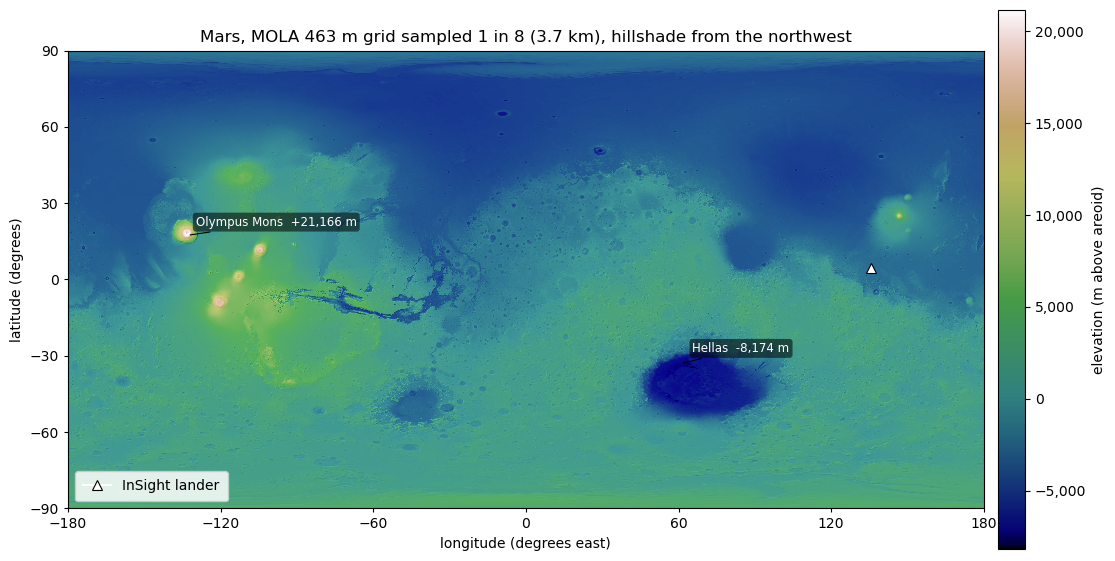

In [26]:
vmin_g, vmax_g = float(np.nanmin(grid)), float(np.nanmax(grid))
filled = np.nan_to_num(grid, nan=vmin_g)
light = colors.LightSource(azdeg=315, altdeg=45)
rgb = light.shade(filled, cmap=plt.get_cmap('gist_earth'), blend_mode='soft',
                  vert_exag=1.5, dx=px, dy=px, vmin=vmin_g, vmax=vmax_g)

fig, ax = plt.subplots(figsize=(12.4, 7.0))
ax.imshow(rgb, extent=(-180, 180, -90, 90), origin='upper', interpolation='nearest')
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xticks(np.arange(-180, 181, 60))
ax.set_yticks(np.arange(-90, 91, 30))
ax.set_xlabel('longitude (degrees east)')
ax.set_ylabel('latitude (degrees)')
ax.tick_params(direction='out', length=3)

for idx, label, dy in [(i_min, f'Hellas  {grid[i_min]:,.0f} m', 8),
                       (i_max, f'Olympus Mons  +{grid[i_max]:,.0f} m', 7)]:
    ax.annotate(label, xy=(lon_axis[idx[1]], lat_axis[idx[0]]),
                xytext=(6, dy), textcoords='offset points', fontsize=8.5,
                color='white', ha='left',
                bbox=dict(boxstyle='round,pad=0.25', fc='black', ec='none', alpha=0.55),
                arrowprops=dict(arrowstyle='-', color='black', lw=0.8))

ax.plot(135.6234, 4.5024, marker='^', color='white', ms=7.5, mec='black', mew=0.8,
        label='InSight lander')
ax.legend(loc='lower left', frameon=True, framealpha=0.85, borderpad=0.6)

sm = ScalarMappable(norm=Normalize(vmin=vmin_g, vmax=vmax_g), cmap='gist_earth')
sm.set_array(filled)
cbar = fig.colorbar(sm, ax=ax, fraction=0.032, pad=0.015)
cbar.set_label('elevation (m above areoid)')
cbar.ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))

ax.set_title('Mars, MOLA 463 m grid sampled 1 in 8 (3.7 km), hillshade from the northwest')
fig.savefig(FIGS / 'fig01_mola_global.png', dpi=200, bbox_inches='tight')
plt.show()

*Figure 1. Global MOLA topography with northwest hillshade. Labels mark the highest and lowest cells in the downsampled grid.*

The global grid places the minimum elevation in Hellas near −8 km and the maximum on Olympus Mons near +21 km. Olympus Mons lies near 133°W, equivalent to 227°E. InSight landed on Elysium Planitia near 4.5°N, 135.6°E.

## 4. Examine the InSight landing site

Zoom in on InSight with a window spanning 12° of latitude and 16° of longitude at MOLA’s native resolution. Compare the elevation map, the north–south profile and the slope map to see how the terrain changes around the landing site. To estimate slope, scale the east–west spacing by the cosine of the landing-site latitude. This correction is about 0.3% at 4.5°N.

In [27]:
def read_box(path, lat_min, lat_max, lon_min, lon_max):
    x_min, y_min = lonlat_to_xy(lon_min, lat_min)
    x_max, y_max = lonlat_to_xy(lon_max, lat_max)
    with rasterio.open(path) as src:
        win = from_bounds(x_min, y_min, x_max, y_max, transform=src.transform)
        arr = src.read(1, window=win).astype('float32')
        transform = src.window_transform(win)
    return arr, transform


lon0, lon1 = 128.0, 144.0
lat0, lat1 = -2.0, 10.0
site_lat, site_lon = 4.5024, 135.6234

z, tr = read_box(MOLA, lat0, lat1, lon0, lon1)
print('window shape :', z.shape, ' pixel size (m):', round(tr.a, 2), round(-tr.e, 2))
z[z < -9000] = np.nan
print(f'elevation in window: {np.nanmin(z):.0f} to {np.nanmax(z):.0f} m')

window shape : (1536, 2048)  pixel size (m): 463.09 463.09
elevation in window: -4404 to 1223 m


In [28]:
px = tr.a
lat_mid = math.radians(0.5 * (lat0 + lat1))
dx = px * math.cos(lat_mid)
dy = -tr.e

dz_dy, dz_dx = np.gradient(z, dy, dx)
slope_pct = np.sqrt(dz_dx ** 2 + dz_dy ** 2) * 100

print(f'spacing used: {dx:.1f} m east-west, {dy:.1f} m north-south')
print(f'median slope: {np.nanmedian(slope_pct):.2f} percent')
print(f'98th pct    : {np.nanpercentile(slope_pct, 98):.2f} percent')

with rasterio.open(MOLA) as src:
    row, col = src.index(x_site, y_site)
    z_site = src.read(1, window=((row, row + 1), (col, col + 1)))[0, 0]
print(f'elevation at the lander: {z_site} m')

spacing used: 462.0 m east-west, 463.1 m north-south
median slope: 0.97 percent
98th pct    : 23.08 percent
elevation at the lander: -2614 m


The elevation near InSight is several kilometres below the areoid. The profile also shows a narrow spike near 1.1°S. Compare it with the elevation map before interpreting it as relief, since a feature restricted to one grid row may be a raster artefact.

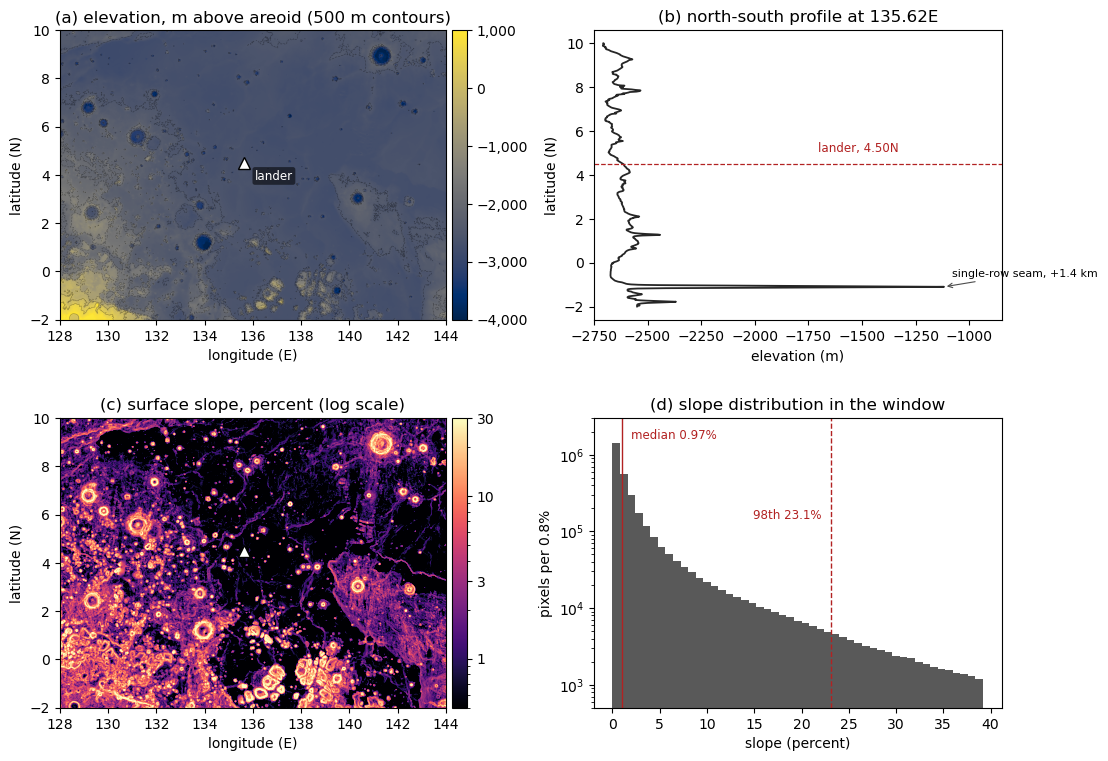

In [29]:
col_site = int((x_site - tr.c) / tr.a)
profile_lat = np.rad2deg((tr.f + (np.arange(z.shape[0]) + 0.5) * tr.e) / R_MARS)
prof = np.nanmean(z[:, max(col_site - 4, 0):col_site + 5], axis=1)

fig = plt.figure(figsize=(12.4, 8.8))
gs = fig.add_gridspec(2, 2, width_ratios=[1.05, 1], hspace=0.34, wspace=0.30)

ax = fig.add_subplot(gs[0, 0])
im = ax.imshow(z, extent=(lon0, lon1, lat0, lat1), origin='upper', cmap='cividis',
               vmin=-4000, vmax=1000)
ax.contour(np.linspace(lon0, lon1, z.shape[1]), np.linspace(lat1, lat0, z.shape[0]),
           z, levels=np.arange(-3500, 800, 500), colors='k', linewidths=0.45, alpha=0.3)
ax.plot(site_lon, site_lat, marker='^', ms=9, color='white', mec='black', mew=1.0)
ax.annotate('lander', xy=(site_lon, site_lat), xytext=(8, -12), textcoords='offset points',
            fontsize=8.5, color='white',
            bbox=dict(boxstyle='round,pad=0.2', fc='black', ec='none', alpha=0.55))
ax.set_xlabel('longitude (E)')
ax.set_ylabel('latitude (N)')
ax.set_title('(a) elevation, m above areoid (500 m contours)')
cbar = fig.colorbar(im, ax=ax, fraction=0.038, pad=0.015)
cbar.ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))

ax = fig.add_subplot(gs[0, 1])
ax.plot(prof, profile_lat, lw=1.3, color='0.15')
ax.axhline(site_lat, color='firebrick', lw=0.9, ls='--')
ax.text(0.55, site_lat + 0.4, 'lander, 4.50N', color='firebrick', fontsize=8.5,
        va='bottom', transform=ax.get_yaxis_transform())
seam = int(np.nanargmax(np.abs(prof - np.nanmedian(prof))))
ax.annotate('single-row seam, +1.4 km', xy=(prof[seam], profile_lat[seam]),
            xytext=(6, 6), textcoords='offset points', fontsize=8,
            ha='left', va='bottom', arrowprops=dict(arrowstyle='->', lw=0.8, color='0.3'))
ax.set_xlim(-2750, -850)
ax.set_xlabel('elevation (m)')
ax.set_ylabel('latitude (N)')
ax.set_title('(b) north-south profile at 135.62E')

ax = fig.add_subplot(gs[1, 0])
im = ax.imshow(slope_pct, extent=(lon0, lon1, lat0, lat1), origin='upper', cmap='magma',
               norm=colors.LogNorm(vmin=0.5, vmax=30))
ax.plot(site_lon, site_lat, marker='^', ms=9, color='white', mec='black', mew=1.0)
ax.set_xlabel('longitude (E)')
ax.set_ylabel('latitude (N)')
ax.set_title('(c) surface slope, percent (log scale)')
cbar = fig.colorbar(im, ax=ax, fraction=0.038, pad=0.015)
cbar.set_ticks([1, 3, 10, 30])
cbar.ax.set_yticklabels(['1', '3', '10', '30'])

ax = fig.add_subplot(gs[1, 1])
vals = slope_pct[np.isfinite(slope_pct)].ravel()
ax.hist(vals, bins=np.arange(0, 40, 0.8), log=True, color='0.35')
med = np.nanmedian(slope_pct)
p98 = np.nanpercentile(slope_pct, 98)
ax.axvline(med, color='firebrick', lw=1.0)
ax.axvline(p98, color='firebrick', lw=1.0, ls='--')
ax.text(med + 1.0, 2.2e6, f'median {med:.2f}%', color='firebrick', fontsize=8.5, va='top')
ax.text(p98 - 1.0, 1.6e5, f'98th {p98:.1f}%', color='firebrick', fontsize=8.5,
        va='center', ha='right')
ax.set_xlabel('slope (percent)')
ax.set_ylabel('pixels per 0.8%')
ax.set_title('(d) slope distribution in the window')
ax.set_ylim(5e2, 3e6)

fig.savefig(FIGS / 'fig02_site_window.png', dpi=200, bbox_inches='tight')
plt.show()

*Figure 2. Elysium Planitia from 128°E to 144°E and 2°S to 10°N. Panels show elevation with 500 m contours, a north–south profile near 135.62°E, slope on a logarithmic colour scale, and the slope distribution.*

Most of the mapped plain has slopes below 5%. Steeper ground is concentrated toward the southwestern highland margin.

## 5. Download the InSight marsquake catalogue

Download the extended QuakeML file from the Marsquake Service V14 release. The parser selects the 1,323 marsquakes for analysis.

In [30]:
MQS_URL = ('https://pds-geosciences.wustl.edu/insight/'
           'urn-nasa-pds-insight_seis/data_derived/mqs_catalog_v14/'
           'events_mars_extended_multiorigin_v14_2023-01-01.cxml')
MQS = DATA / 'mqs_v14_mars_extended.cxml'

fetch(MQS_URL, MQS, min_bytes=30_000_000)
print(f'file size: {MQS.stat().st_size / 1e6:.1f} MB')

cached  mqs_v14_mars_extended.cxml  36.9 MB
file size: 36.9 MB


A QuakeML event can contain several origin solutions. Read the event type from the event record, then use `preferredOriginID` to select the origin from which to extract location quality and epicentral distance.

In [31]:
BED = '{http://quakeml.org/xmlns/bed/1.2}'
MARS = '{http://quakeml.org/xmlns/bed/1.2/mars}'

TYPE_MAP = {'LOW_FREQUENCY': 'LF', 'BROADBAND': 'BB', 'HIGH_FREQUENCY': 'HF',
            '2.4_HZ': '2.4', 'VERY_HIGH_FREQUENCY': 'VF'}


def text_of(node, path):
    if node is None:
        return None
    child = node.find(path)
    if child is None or child.text is None:
        return None
    return child.text.strip()


def tail(uri):
    # last token of a vocabulary URI, e.g. ...MarsEventType#BROADBAND -> BROADBAND
    if not uri:
        return None
    return uri.rsplit('#', 1)[-1]


def preferred_origin(ev):
    pref = text_of(ev, BED + 'preferredOriginID')
    for cand in ev.findall(BED + 'origin'):
        if cand.get('publicID') == pref:
            return cand
    return ev.find(BED + 'origin')


def parse_catalogue(path):
    tree = ET.parse(str(path))
    rows = []
    for ev in tree.iter(BED + 'event'):
        name = None
        for desc in ev.findall(BED + 'description'):
            if text_of(desc, BED + 'type') == 'earthquake name':
                name = text_of(desc, BED + 'text')
        if not name or not name.startswith('S'):
            continue
        origin = preferred_origin(ev)
        lat_raw = text_of(origin, BED + 'latitude')
        lon_raw = text_of(origin, BED + 'longitude')
        lat_v = float(lat_raw) if lat_raw else np.nan
        lon_v = float(lon_raw) if lon_raw else np.nan
        if np.isfinite(lon_v):
            lon_v = ((lon_v + 180.0) % 360.0) - 180.0
        dist_raw = text_of(origin, MARS + 'distance/' + MARS + 'value')
        mags = {}
        for mag in ev.findall(BED + 'magnitude'):
            mag_type = text_of(mag, BED + 'type')
            mag_value = text_of(mag, BED + 'mag/' + BED + 'value')
            if mag_type and mag_value:
                mags[mag_type] = float(mag_value)
        rows.append({
            'name': name,
            'sol': int(name[1:5]) if name and name[1:5].isdigit() else np.nan,
            'lat': lat_v,
            'lon': lon_v,
            'event_type': TYPE_MAP.get(tail(text_of(ev, MARS + 'type')),
                                       tail(text_of(ev, MARS + 'type'))),
            'quality': tail(text_of(origin, MARS + 'locationQuality')),
            'distance_deg': float(dist_raw) if dist_raw else np.nan,
            'mags': mags,
        })
    return rows

In [32]:
events = parse_catalogue(MQS)
print('S-series marsquakes:', len(events))
assert len(events) == 1323

print('with coordinates:', sum(1 for e in events if np.isfinite(e['lat'])))
print('with distance   :', sum(1 for e in events if np.isfinite(e['distance_deg'])))

types, quals = {}, {}
for e in events:
    types[e['event_type']] = types.get(e['event_type'], 0) + 1
    quals[e['quality']] = quals.get(e['quality'], 0) + 1
print('types  ', {k: types[k] for k in sorted(types, key=types.get, reverse=True)})
print('quality', {k: quals[k] for k in sorted(quals, key=lambda s: str(s))})

S-series marsquakes: 1323
with coordinates: 0
with distance   : 672
types   {'2.4': 989, 'HF': 162, 'VF': 74, 'LF': 59, 'BB': 39}
quality {'A': 14, 'B': 175, 'C': 501, 'D': 633}


The marsquake classes are LF (low frequency), BB (broadband), HF (high frequency), 2.4 (2.4 Hz resonance) and VF (very high frequency). The A–D quality grades describe confidence in the event and its phase information.

## 6. Explore event counts and distances

Plot detections by Martian sol to see how the catalogue accumulated over the mission. Then look at the distance distribution for records with an epicentral distance estimate. In an event name such as S1415a, the digits identify the sol and the final letter distinguishes events on the same sol.

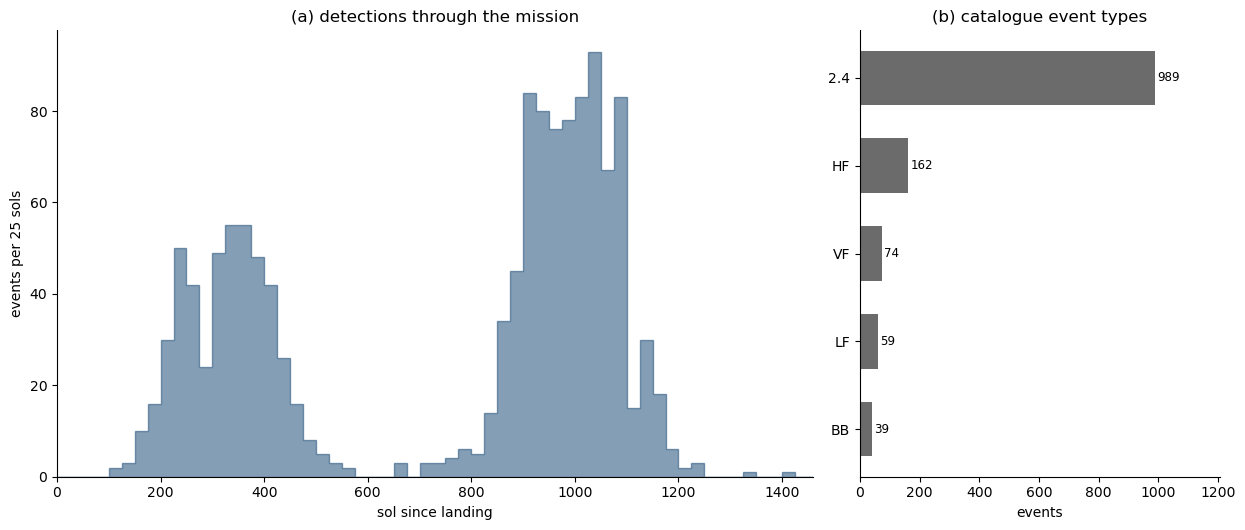

In [33]:
sols = np.array([e['sol'] for e in events], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.4), gridspec_kw={'width_ratios': [2.1, 1]})

ax = axes[0]
bins = np.arange(0, 1480, 25)
ax.hist(sols, bins=bins, histtype='stepfilled', color='#1f4e79', alpha=0.55,
        edgecolor='#1f4e79', lw=1.0, label=f'S series, {len(events):,} marsquakes')
ax.set_xlabel('sol since landing')
ax.set_ylabel('events per 25 sols')
ax.set_xlim(0, 1460)
ax.set_title('(a) detections through the mission')

ax = axes[1]
order = sorted(types, key=types.get)
vals = [types[k] for k in order]
bars = ax.barh([str(k) for k in order], vals, color='0.42', height=0.62)
for bar, val in zip(bars, vals):
    ax.text(val + 8, bar.get_y() + bar.get_height() / 2, f'{val:,}', va='center', fontsize=8.5)
ax.set_xlim(0, max(vals) * 1.22)
ax.set_xlabel('events')
ax.set_title('(b) catalogue event types')

for ax in axes:
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

fig.tight_layout()
fig.savefig(FIGS / 'fig03_catalogue_counts.png', dpi=200, bbox_inches='tight')
plt.show()

*Figure 3. Distribution of the 1,323 marsquakes in the InSight V14 catalogue. (a) Event counts in 25-sol bins since landing. (b) Total event counts by catalogue class.*

Detection varies with wind noise, time of day and season. Interpret gaps and peaks in the histogram in light of those changes in detectability.

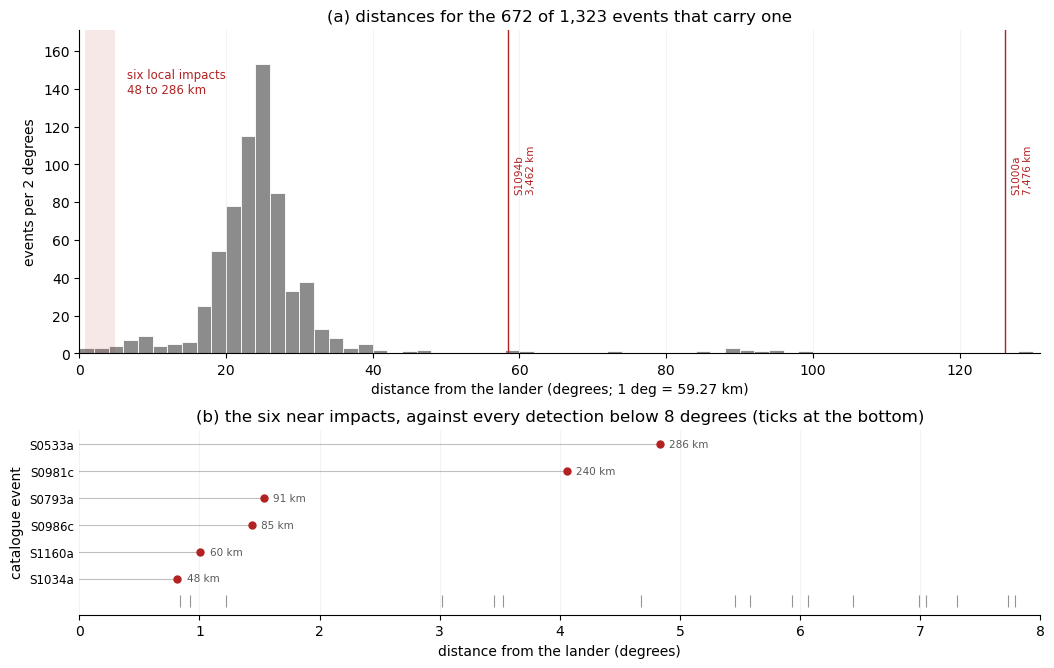

In [34]:
IMPACTS = [
    ('S0533a', 286.3, 11.9, 'cluster', 'ESP_070864_1895'),
    ('S0793a', 91.0, 3.9, 'single', 'ESP_070073_1845'),
    ('S0981c', 240.5, 7.2, 'single', 'ESP_072644_1805'),
    ('S0986c', 85.0, 6.1, 'cluster', 'ESP_072222_1840'),
    ('S1034a', 48.2, 9.2, 'single', 'ESP_074701_1840'),
    ('S1160a', 59.6, 3.2, 'cluster', 'ESP_076877_1850'),
    ('S1000a', 7475.9, 140.0, 'cluster', 'ESP_073522_2185'),
    ('S1094b', 3462.0, 150.0, 'single', 'ESP_073077_2155'),
]

dist_deg = np.array([e['distance_deg'] for e in events], dtype=float)
have = np.isfinite(dist_deg)

fig = plt.figure(figsize=(12.4, 7.6))
gs = fig.add_gridspec(2, 1, height_ratios=[1.75, 1], hspace=0.30)

ax = fig.add_subplot(gs[0])
counts, _, _ = ax.hist(dist_deg[have], bins=np.arange(0, 132, 2), color='0.55',
                       edgecolor='white', lw=0.6)
top = counts.max()
near = [dist_km for name, dist_km, diam, kind, pid in IMPACTS if dist_km / DEG_KM <= 8]
ax.axvspan(min(near) / DEG_KM, max(near) / DEG_KM, color='firebrick', alpha=0.10, lw=0)
ax.text(6.5, 0.88 * top * 1.12, 'six local impacts\n48 to 286 km', fontsize=8.5,
        color='firebrick', va='top', ha='left')
for name, dist_km, diam, kind, pid in IMPACTS:
    x = dist_km / DEG_KM
    if x > 10:
        ax.axvline(x, color='firebrick', lw=1.0)
        ax.annotate(f'{name}\n{dist_km:,.0f} km', xy=(x, top * 0.55), xytext=(5, 0),
                    textcoords='offset points', rotation=90, fontsize=7.5,
                    color='firebrick', ha='left', va='bottom')
ax.set_xlim(0, 131)
ax.set_ylim(0, top * 1.12)
ax.set_xlabel('distance from the lander (degrees; 1 deg = 59.27 km)')
ax.set_ylabel('events per 2 degrees')
ax.set_title(f'(a) distances for the {have.sum():,} of {len(events):,} events that carry one')

ax = fig.add_subplot(gs[1])
sub = dist_deg[have & (dist_deg <= 8)]
near_impacts = sorted([(n, d) for n, d, di, k, p in IMPACTS if d / DEG_KM <= 8],
                      key=lambda t: t[1])
for i, (name, dist_km) in enumerate(near_impacts):
    x = dist_km / DEG_KM
    ax.plot([0, x], [i, i], color='0.75', lw=0.8, zorder=1)
    ax.plot(x, i, 'o', ms=5, color='firebrick', zorder=2)
    ax.text(x + 0.08, i, f'{dist_km:.0f} km', va='center', fontsize=7.5, color='0.35')
ax.plot(sub, np.full_like(sub, -0.85), '|', ms=8, mew=0.8, color='0.5', alpha=0.85)
ax.set_yticks(range(len(near_impacts)))
ax.set_yticklabels([n for n, _ in near_impacts], fontsize=8.5)
ax.set_ylim(-1.35, len(near_impacts) - 0.45)
ax.set_xlim(0, 8)
ax.set_xlabel('distance from the lander (degrees)')
ax.set_ylabel('catalogue event')
ax.set_title('(b) the six near impacts, against every detection below 8 degrees (ticks at the bottom)')
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.tick_params(axis='y', length=0)

for ax in fig.axes:
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.18, lw=0.6, axis='x')

fig.savefig(FIGS / 'fig04_impacts_distance.png', dpi=200, bbox_inches='tight')
plt.show()

*Figure 4. Distances from InSight for the 672 catalogue records with distance estimates. The lower panel focuses on distances below 8°. The eight impact distances are from Daubar et al. (2024, Table 1).*

Most reported distances fall between 15° and 40°. The distribution describes the subset with distance estimates and is influenced by detection and location thresholds. Distance alone locates an event on a circle around InSight.

## 7. Examine fresh impact craters

Fresh craters can show raised rims, blast zones and ejecta rays in orbital images. Before-and-after imagery helped confirm the impacts associated with S1000a and S1094b. The 24 December 2021 impact associated with S1094b produced a crater about 150 m wide and 21 m deep.

A 150 m crater spans about 0.32 pixels at 463 m per pixel. Inspect its shape in the HiRISE image, then use the MOLA grid to estimate the diameter of Jezero, whose published diameter of 45 km spans about 97 pixels.

In [35]:
for diam in (3.2, 11.9, 140.0, 150.0):
    print(f'{diam:6.1f} m  ->  {diam / 463:.3f} MOLA pixels')

   3.2 m  ->  0.007 MOLA pixels
  11.9 m  ->  0.026 MOLA pixels
 140.0 m  ->  0.302 MOLA pixels
 150.0 m  ->  0.324 MOLA pixels


HiRISE groups browse products by orbit. For example, orbit 073077 falls in `ORB_073000_073099`. The function below builds the browse URL from the product identifier.

If the server is unavailable, save the supplied `ESP_073077_2155_RED.browse.jpg` in `mars_data/` under the working directory printed in Step 1. This cell will use the local copy.

In [36]:
import subprocess

def hirise_browse(product_id, band='RED'):
    prefix, orb = product_id.split('_')[0], product_id.split('_')[1]
    folder = f'ORB_{orb[:3]}000_{orb[:3]}099'
    return (f'https://hirise-pds.lpl.arizona.edu/PDS/EXTRAS/RDR/{prefix}/'
            f'{folder}/{product_id}/{product_id}_{band}.browse.jpg')


BROWSE_URL = hirise_browse('ESP_073077_2155')
BROWSE = DATA / 'ESP_073077_2155_RED.browse.jpg'
if not BROWSE.is_file():
    partial = BROWSE.with_suffix(".jpg.part")
    subprocess.run(
        [
            "curl", "--fail", "--location", "--retry", "2",
            "--connect-timeout", "20", "--max-time", "180",
            "--output", str(partial), BROWSE_URL,
        ],
        check=True,
    )
    partial.replace(BROWSE)

print(f"HiRISE image: {BROWSE}")


HiRISE image: /Users/qilidai/Desktop/CUHK/ug_students/mars_impact/mars_data/ESP_073077_2155_RED.browse.jpg


image: (2048, 3790) L


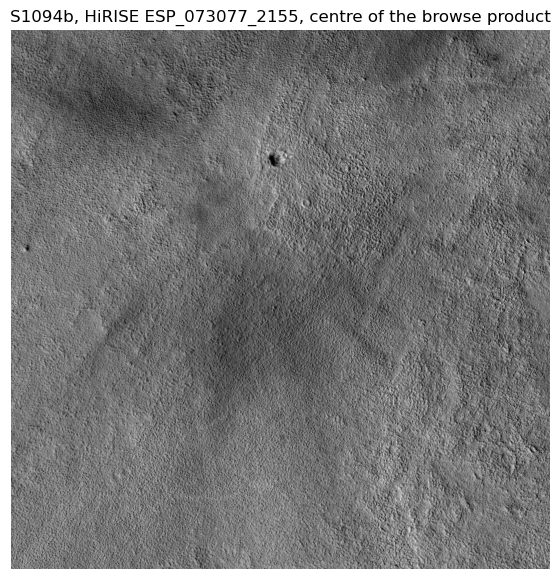

In [37]:
from PIL import Image

img = Image.open(BROWSE)
arr = np.asarray(img.convert('L'))
print('image:', img.size, img.mode)

h, w = arr.shape
half = 700
crop = arr[h // 2 - half:h // 2 + half, w // 2 - half:w // 2 + half]

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(crop, cmap='gray')
ax.set_title('S1094b, HiRISE ESP_073077_2155, centre of the browse product')
ax.axis('off')
fig.savefig(FIGS / 'fig05_s1094b.png', dpi=180, bbox_inches='tight')
plt.show()

*Figure 5. HiRISE browse image of the fresh crater associated with S1094b.*

In the HiRISE browse image, look for the crater rim and the ejecta around it. Use the published higher-resolution measurements for the crater’s diameter and depth.

For Jezero, average elevation in concentric rings about the crater centre. Estimate the rim radius from the maximum of this radial profile outside the central 8 km, then double the radius to estimate the diameter.

In [44]:
def read_xy_box(path, x_min, y_min, x_max, y_max):
    with rasterio.open(path) as src:
        win = from_bounds(x_min, y_min, x_max, y_max, transform=src.transform)
        arr = src.read(1, window=win).astype('float64')
        tr = src.window_transform(win)
    arr[arr < -9000] = np.nan
    return arr, tr


def radial_profile(path, lat_c, lon_c, r_max_km, dr_km=1.0):
    xc, yc = lonlat_to_xy(lon_c, lat_c)
    r_m = r_max_km * 1000.0
    box, tr = read_xy_box(path, xc - r_m, yc - r_m, xc + r_m, yc + r_m)

    xs = tr.c + (np.arange(box.shape[1]) + 0.5) * tr.a
    ys = tr.f + (np.arange(box.shape[0]) + 0.5) * tr.e
    xg, yg = np.meshgrid(xs, ys)
    radius = np.sqrt((xg - xc) ** 2 + (yg - yc) ** 2) / 1000.0

    edges = np.arange(0, r_max_km + dr_km, dr_km)
    idx = np.digitize(radius.ravel(), edges) - 1
    prof = np.full(len(edges) - 1, np.nan)
    for k in range(len(prof)):
        vals = box.ravel()[idx == k]
        vals = vals[np.isfinite(vals)]
        if vals.size:
            prof[k] = vals.mean()
    centres = 0.5 * (edges[1:] + edges[:-1])
    return centres, prof

In [45]:
JEZ_LAT, JEZ_LON, JEZ_D_KM = 18.38, 77.68, 45.0

r_km, z_prof = radial_profile(MOLA, JEZ_LAT, JEZ_LON, 55.0, dr_km=1.0)
mask = r_km > 8
r_rim = r_km[mask][np.nanargmax(z_prof[mask])]
d_meas = 2 * r_rim

print(f'rim radius  : {r_rim:.1f} km')
print(f'diameter    : {d_meas:.1f} km   (published: {JEZ_D_KM:.1f} km)')
print(f'error       : {100 * (d_meas - JEZ_D_KM) / JEZ_D_KM:+.1f} percent')

rim radius  : 25.5 km
diameter    : 51.0 km   (published: 45.0 km)
error       : +13.3 percent


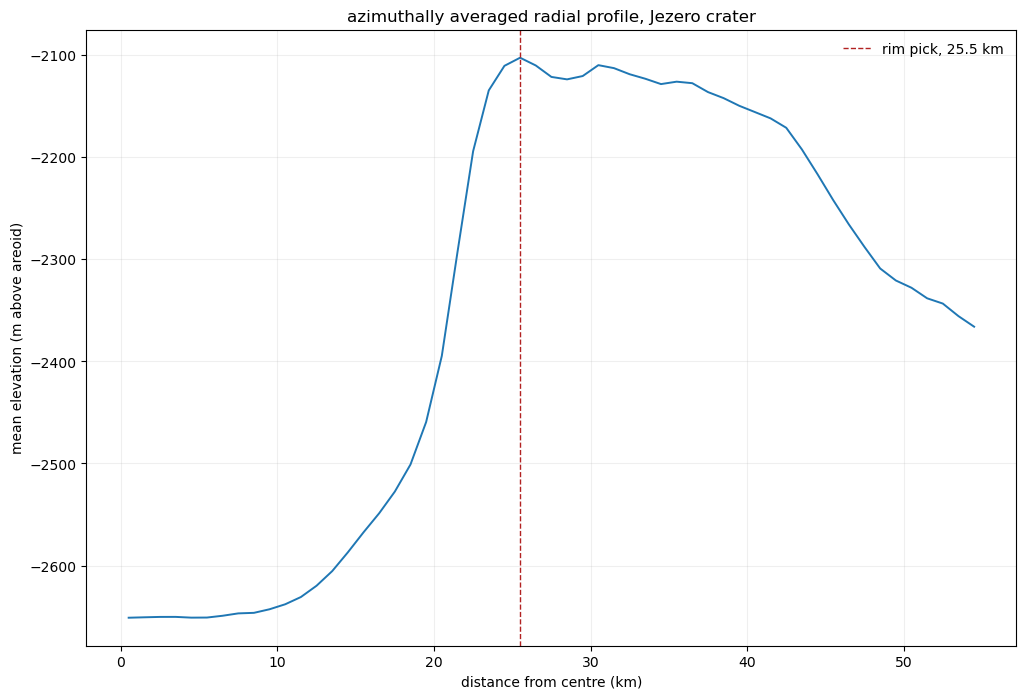

In [46]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(r_km, z_prof, lw=1.4)
ax.axvline(r_rim, color='firebrick', ls='--', lw=1, label=f'rim pick, {r_rim:.1f} km')
ax.set_xlabel('distance from centre (km)')
ax.set_ylabel('mean elevation (m above areoid)')
ax.set_title('azimuthally averaged radial profile, Jezero crater')
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.savefig(FIGS / 'fig06_jezero_profile.png', dpi=180)
plt.show()

*Figure 6. Mean elevation around Jezero crater in 1 km radial bins. The marker shows the selected rim radius. The published 45 km diameter is shown for comparison.*

The profile gives a radius of 25.5 km and a diameter of 51 km, about 13% larger than the published 45 km diameter. The estimate depends on the chosen crater centre, how the rim is defined and the topography inside the crater. Use the map to check whether the radial peak follows the rim.

## 8. Compare crater diameter and seismic magnitude

The sample contains six local VF events within 300 km and two distant BB events at approximately 3,460 and 7,476 km. Use the published effective crater diameters and the magnitudes in the V14 catalogue. The code prefers `MW` and reports which magnitude type it selects, since the catalogue can provide multiple estimates for one event.

In [47]:
BED_NS = BED


def preferred_magnitude(event):
    order = ['MW', 'Mw', 'MWspec', 'M2.4', 'MbS', 'MbP']
    m = event['mags']
    for key in order:
        if key in m:
            return key, m[key]
    if m:
        key = sorted(m, key=m.get, reverse=True)[0]
        return key, m[key]
    return None, np.nan


print('Table 1. The eight confirmed impacts: published distance and effective crater diameter, catalogue event type and preferred magnitude.')
print()
print(f'{"event":8s} {"distance":>9s} {"diam":>7s} {"type":>10s} {"mag":>5s}  {"available":>30s}')
rows = []
for name, dist_km, diam, kind, pid in IMPACTS:
    ev = next(e for e in events if e['name'] == name)
    key, val = preferred_magnitude(ev)
    rows.append((name, dist_km, diam, ev['event_type'], key, val))
    print(f'{name:8s} {dist_km:9.1f} {diam:7.1f} {str(ev["event_type"]):>10s} '
          f'{val:5.2f}  {",".join(sorted(ev["mags"])):>30s}')
print()
print('Distances and diameters: Daubar et al. (2024), Table 1. Magnitudes and types: MQS V14.')

Table 1. The eight confirmed impacts: published distance and effective crater diameter, catalogue event type and preferred magnitude.

event     distance    diam       type   mag                       available
S0533a       286.3    11.9         VF  2.30                  M2.4,MW,MWspec
S0793a        91.0     3.9         VF  1.40                  M2.4,MW,MWspec
S0981c       240.5     7.2         VF  1.60                  M2.4,MW,MWspec
S0986c        85.0     6.1         VF  1.20                  M2.4,MW,MWspec
S1034a        48.2     9.2         VF  3.00                  M2.4,MW,MWspec
S1160a        59.6     3.2         VF  1.50                  M2.4,MW,MWspec
S1000a      7475.9   140.0         BB  4.10               MW,MWspec,MbP,MbS
S1094b      3462.0   150.0         BB  4.00               MW,MWspec,MbP,MbS

Distances and diameters: Daubar et al. (2024), Table 1. Magnitudes and types: MQS V14.


All eight events have an `MW` estimate. For S1034a, the catalogue gives 3.0 for `MW` and 2.4 for `MWspec`. This difference illustrates the sensitivity of the comparison to the magnitude scale.

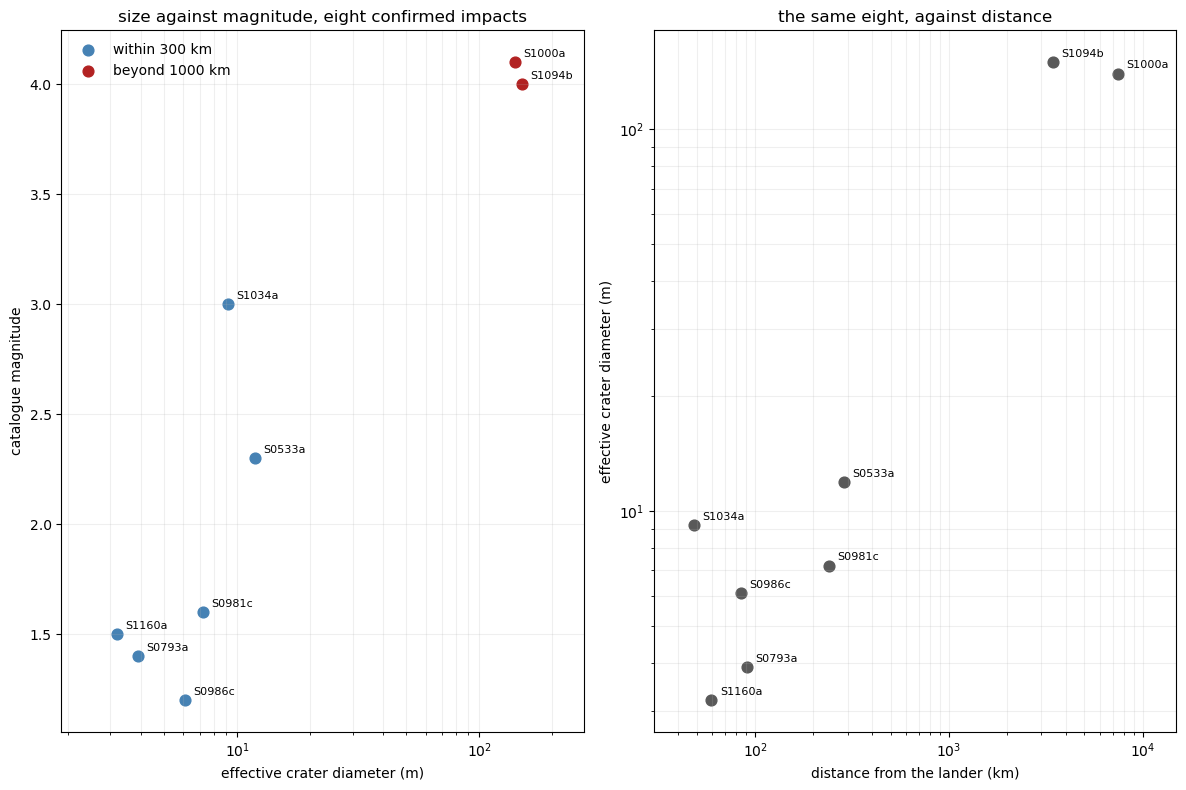

In [48]:
labels = [r[0] for r in rows]
diam = np.array([r[2] for r in rows])
dist = np.array([r[1] for r in rows])
mag = np.array([r[5] for r in rows], dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12, 8))

ax = axes[0]
near = dist < 1000
ax.scatter(diam[near], mag[near], s=60, color='steelblue', label='within 300 km')
ax.scatter(diam[~near], mag[~near], s=60, color='firebrick', label='beyond 1000 km')
for name, d, m, dd in zip(labels, diam, mag, dist):
    ax.annotate(name, (d, m), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.set_xscale('log')
ax.set_xlabel('effective crater diameter (m)')
ax.set_ylabel('catalogue magnitude')
ax.set_title('size against magnitude, eight confirmed impacts')
ax.set_xlim(diam.min() / 1.7, diam.max() * 1.8)
ax.legend(frameon=False)
ax.grid(alpha=0.2, which='both')

ax = axes[1]
ax.scatter(dist, diam, s=60, color='0.35')
for name, d, dd in zip(labels, diam, dist):
    ax.annotate(name, (dd, d), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('distance from the lander (km)')
ax.set_ylabel('effective crater diameter (m)')
ax.set_title('the same eight, against distance')
ax.set_xlim(dist.min() / 1.6, dist.max() * 2.0)
ax.grid(alpha=0.2, which='both')

fig.tight_layout()
fig.savefig(FIGS / 'fig07_size_magnitude.png', dpi=180)
plt.show()

*Figure 7. Effective crater diameter versus catalogue magnitude and distance from InSight for eight confirmed impacts. Diameters and distances are from Daubar et al. (2024, Table 1). Magnitudes and event types are from the InSight V14 catalogue.*

In [49]:
from scipy.stats import spearmanr

rho_all, p_all = spearmanr(diam, mag)
rho_near, p_near = spearmanr(diam[near], mag[near])
print(f'all eight : rho = {rho_all:+.2f}, p = {p_all:.2f}, n = {len(diam)}')
print(f'near six  : rho = {rho_near:+.2f}, p = {p_near:.2f}, n = {near.sum()}')

print('\nfallback check, VF magnitudes lowered by 0.5:')
rho_vf, p_vf = spearmanr(diam, mag - 0.5 * np.array([r[3] == 'VF' for r in rows], dtype=float))
print(f'all eight : rho = {rho_vf:+.2f}, p = {p_vf:.2f}')

all eight : rho = +0.86, p = 0.01, n = 8
near six  : rho = +0.71, p = 0.11, n = 6

fallback check, VF magnitudes lowered by 0.5:
all eight : rho = +0.86, p = 0.01


The Spearman rank correlation is about 0.86 across all eight events and 0.71 for the six local events. The change shows how much the result depends on which events are included. With only six local events and a p-value of about 0.11, evidence for a diameter–magnitude trend in the local subset is limited.

Crater diameter depends on impact energy and target properties. The seismic magnitude estimate also depends on the source, propagation path and magnitude scale. Compare the two distant impacts with the local group to see how they affect the pattern.

## Sources

Böse, M., et al. (2021). Magnitude scales for marsquakes calibrated from InSight data. *Bulletin of the Seismological Society of America.*


Ceylan, S., et al. (2023). Mapping the seismicity of Mars with InSight. *Journal of Geophysical Research: Planets*, 128(8), e2023JE007826. [https://doi.org/10.1029/2023JE007826](https://doi.org/10.1029/2023JE007826)


Daubar, I. J., et al. (2022). New craters on Mars: an updated catalog. *Journal of Geophysical Research: Planets*, 127(7), e2021JE007145. [https://doi.org/10.1029/2021JE007145](https://doi.org/10.1029/2021JE007145)


Daubar, I. J., et al. (2024). Seismically detected cratering on Mars: enhanced recent impact flux? *Science Advances*, 10, eadk7615. [https://doi.org/10.1126/sciadv.adk7615](https://doi.org/10.1126/sciadv.adk7615)


Garcia, R. F., et al. (2022). Newly formed craters on Mars located using seismic and acoustic wave data from InSight. *Nature Geoscience*, 15, 774-780.


Grindrod, P. M., et al. (2024). Extensive secondary cratering from the InSight sol 1034a impact event. *Journal of Geophysical Research: Planets*, 129(12), e2024JE008535. [https://doi.org/10.1029/2024JE008535](https://doi.org/10.1029/2024JE008535)


InSight Marsquake Service (2023). *Mars seismic catalogue, InSight mission; V14 2023-04-01.* ETHZ, IPGP, JPL, ICL, University of Bristol. [https://doi.org/10.12686/a21](https://doi.org/10.12686/a21)


Kim, D., et al. (2022). Surface waves and crustal structure on Mars. *Science*, 378, 417-421. [https://doi.org/10.1126/science.abq7157](https://doi.org/10.1126/science.abq7157)


Neumann, G. A., et al. (2001). Crossover analysis of Mars Orbiter Laser Altimeter data. *Journal of Geophysical Research*, 106(E10), 23753-23768. [https://doi.org/10.1029/2000JE001381](https://doi.org/10.1029/2000JE001381)


Posiolova, L. V., et al. (2022). Largest recent impact craters on Mars: orbital imaging and surface seismic co-investigation. *Science*, 378(6618), 412-417. [https://doi.org/10.1126/science.abq7704](https://doi.org/10.1126/science.abq7704)


Robbins, S. J., and Hynek, B. M. (2012). A new global database of Mars impact craters >= 1 km. *Journal of Geophysical Research*, 117, E05004. [https://doi.org/10.1029/2011JE003966](https://doi.org/10.1029/2011JE003966)


Smith, D. E., et al. (2001). Mars Orbiter Laser Altimeter: experiment summary after the first year of global mapping of Mars. *Journal of Geophysical Research*, 106(E10), 23689-23722. [https://doi.org/10.1029/2000JE001364](https://doi.org/10.1029/2000JE001364)


Song, X., et al. (2026). How large are marsquakes? Revisiting magnitude scaling and implications for marsquakes and meteoroid impacts. *Journal of Geophysical Research: Planets.*


USGS Astrogeology Science Center. *Mars MGS MOLA DEM 463m.* [https://astrogeology.usgs.gov/search/map/mars_mgs_mola_dem_463m](https://astrogeology.usgs.gov/search/map/mars_mgs_mola_dem_463m)


PDS Geosciences Node. *InSight SEIS bundle*, data_derived/mqs_catalog_v14. [https://pds-geosciences.wustl.edu/insight/urn-nasa-pds-insight_seis/](https://pds-geosciences.wustl.edu/insight/urn-nasa-pds-insight_seis/)


Fong, K. H., and Dai, Q. A. *Tutorial on lunar seismic data.* CU Seismology Lab. [https://cuseismolab.github.io/Tutorial-post/lunar-seismic/](https://cuseismolab.github.io/Tutorial-post/lunar-seismic/)


University of Arizona HiRISE. *ESP_073077_2155.* [https://www.uahirise.org/ESP_073077_2155](https://www.uahirise.org/ESP_073077_2155)

## Notes on reproducibility

The data files remain in `mars_data/` between runs. To refresh one input, remove its cached file and rerun the download cell. The notebook generates Figures 1–7 from the cached inputs and the impact parameters cited above.